# Lab 01 — Exploratory Data Analysis

*Machine Learning and Data Mining — Claudio Sartori, University of Bologna*

Part A is adapted from the *Python Data Science Handbook* by Jake VanderPlas
([book](http://shop.oreilly.com/product/0636920034919.do), [GitHub](https://github.com/jakevdp/PythonDataScienceHandbook));
text released under [CC-BY-NC-ND](https://creativecommons.org/licenses/by-nc-nd/3.0/us/legalcode), code under the [MIT license](https://opensource.org/licenses/MIT).

## Goal of this lab

Apply the **EDA checklist** of Lecture 6 in code, with the tools of Lecture 7.

| # | Checklist item | Part A — Iris | Part B — NordicMart |
|---|---|---|---|
| 1 | Kind of data set; type of every column; identifiers out | A1 | B1 |
| 2 | Summaries and one plot per variable | A2 | B2 |
| 3 | Missing values: how many, and why | A3 | B3 |
| 4 | Codes, defaults, impossible values, outliers, duplicates | A3 | B3 |
| 5 | The target: balance | A4 | B4 |
| 6 | Each feature × target; correlations; confounders | A5 | B5 |
| 7 | Write down findings → preparation actions | A6 | B6 |

- **Part A (≈ 40 min)** — the Iris data set: small and clean, to learn the calls.
- **Part B (≈ 60 min)** — the NordicMart customer table seen in the lecture: real-looking problems, to practice the judgement.
- Exercises marked ★ are optional: do them if you have time, or at home.

### How to work (notebook good practices)

- Write code in the empty cells; write **answers and findings in markdown cells**, not in comments.
- Never modify the raw data: the raw tables are loaded once and **not changed**; every fix goes into a working copy.
- Before closing: **Kernel → Restart & Run All**. The notebook must run from top to bottom without errors.

## Setup

All imports, paths and constants in one place. Adjust `DATA_DIR` if your data folder is somewhere else.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_DIR = Path("../../data")                      # relative path: works on any machine
IRIS_FILE = DATA_DIR / "iris.csv"
NORDICMART_FILE = DATA_DIR / "nordicmart_customers.csv"
SEED = 42                                          # fixed seed: same "random" results at every run

pd.set_option("display.precision", 2)
plt.rcParams["figure.figsize"] = (8, 4)

print("pandas", pd.__version__, "| numpy", np.__version__, "| seaborn", sns.__version__)

pandas 3.0.5 | numpy 2.5.3 | seaborn 0.13.2


# Part A — Iris

The [Iris data set](https://en.wikipedia.org/wiki/Iris_flower_data_set), analysed by Ronald Fisher in 1936:
measurements of 150 iris flowers of three species.
Your data folder contains two files, `iris.csv` and `iris.names`.

## A1. Kind of data set and type of every column

### Look at the raw file before loading it

Open `iris.csv` and `iris.names` as text (a text editor, or the cell below) and answer:

1. is it a `csv` file or something else?
1. what is the *separator* character (`,`, `;`, `\t`, ...)?
1. is there a *header*, i.e. a first row with the column names?
1. if there is no header, where can you find reasonable names? (for UCI data sets: the `.names` file)
1. is the data set supervised? which column is the *target*?

In [2]:
# the first lines of the file, as plain text
with open(IRIS_FILE) as f:
    for _ in range(5):
        print(f.readline(), end="")

5.1,3.5,1.4,0.2,Iris-setosa
4.9,3.0,1.4,0.2,Iris-setosa
4.7,3.2,1.3,0.2,Iris-setosa
4.6,3.1,1.5,0.2,Iris-setosa
5.0,3.6,1.4,0.2,Iris-setosa


**Answer.** A `csv` file, comma-separated, **no header**: the first row is already data.
The column names are in `iris.names`: sepal length, sepal width, petal length, petal width (cm) and class.
It is supervised: the target is the **class** (the species).

### Load the data set into a pandas `DataFrame`

- documentation: [`pd.read_csv()`](https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html) — check how to give the column names when there is no header
- name the DataFrame `iris`; it is the raw table and **will not be modified**

In [3]:
names = ["sepal length", "sepal width", "petal length", "petal width", "class"]
iris = pd.read_csv(IRIS_FILE, header=None, names=names)

Show the column names, the number of rows and columns (attribute `shape`) and the type of each column (`dtypes`, or `info()`).
Then store the size of the data set in two variables, `n_samples` and `n_features`:

- each row is a single flower: a *sample*; the number of rows is `n_samples`
- each column that describes the samples is a *feature*; `class` is **not** a feature but the *target*, so `n_features` is the number of columns minus one

Why these two names? They are the standard vocabulary of scikit-learn: from the next labs on, every model expects the features
as a table of shape `(n_samples, n_features)` and the target as a column of length `n_samples`, and you will read these names
in every docstring. Separating features from target (and, in Part B, from identifiers) is the first decision of any analysis.

In [4]:
print(iris.columns.tolist())
print(f"There are {iris.shape[0]} rows and {iris.shape[1]} columns")
n_samples, n_features = iris.shape[0], iris.shape[1] - 1     # 'class' is the target, not a feature
print(f"n_samples = {n_samples}, n_features = {n_features} (+ 1 target column)")
iris.info()

['sepal length', 'sepal width', 'petal length', 'petal width', 'class']
There are 150 rows and 5 columns
n_samples = 150, n_features = 4 (+ 1 target column)
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal length  150 non-null    float64
 1   sepal width   150 non-null    float64
 2   petal length  150 non-null    float64
 3   petal width   150 non-null    float64
 4   class         150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


Show the first rows with `head()`, then a random sample of rows with `sample(5)`.
Run the `sample` cell twice: what happens? Then add `random_state=SEED` and run it twice again.

In [5]:
iris.head()

,sepal length,sepal width,petal length,petal width,class
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [6]:
iris.sample(5, random_state=SEED)

,sepal length,sepal width,petal length,petal width,class
73,6.1,2.8,4.7,1.2,Iris-versicolor
18,5.7,3.8,1.7,0.3,Iris-setosa
118,7.7,2.6,6.9,2.3,Iris-virginica
78,6.0,2.9,4.5,1.5,Iris-versicolor
76,6.8,2.8,4.8,1.4,Iris-versicolor


**Question.** For every column, give its type on the scale of Lecture 6 (nominal, ordinal, interval, ratio)
and say whether it is discrete or continuous. Is there an identifier to drop?

**Answer.** The four measurements are **ratio**, continuous (a length has a true zero; 4 cm is twice 2 cm).
`class` is **nominal**, discrete, with 3 values: it is the target. There is no identifier column.
Without `random_state` every run of `sample` shows different rows: results that change at every run are not reproducible.

## A2. Summaries and one plot per variable

The `describe()` method gives a short summary of every numeric column.
Look in the [documentation](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.describe.html)
for the parameter that includes the non-numeric columns too.

In [7]:
iris.describe(include="all")

,sepal length,sepal width,petal length,petal width,class
count,150.00,150.00,150.00,150.00,150
unique,NaN,NaN,NaN,NaN,3
top,NaN,NaN,NaN,NaN,Iris-setosa
freq,NaN,NaN,NaN,NaN,50
mean,5.84,3.06,3.76,1.20,NaN
std,0.83,0.44,1.77,0.76,NaN
min,4.30,2.00,1.00,0.10,NaN
25%,5.10,2.80,1.60,0.30,NaN
50%,5.80,3.00,4.35,1.30,NaN
75%,6.40,3.30,5.10,1.80,NaN


**Question.** For which columns are mean and median (50%) close? What does it tell you about the shape of the distribution?

**Answer.** For the sepal measurements mean and median are almost equal: roughly symmetric distributions.
For petal length (mean 3.76, median 4.35) and petal width the mean is *below* the median: the distribution is not symmetric —
the histograms show why: two separate groups.

Draw a histogram of every numeric column with `DataFrame.hist()` (use `figsize` to adjust the size).
Then redraw only `petal length` with 5, 15 and 40 bins: does the story change?

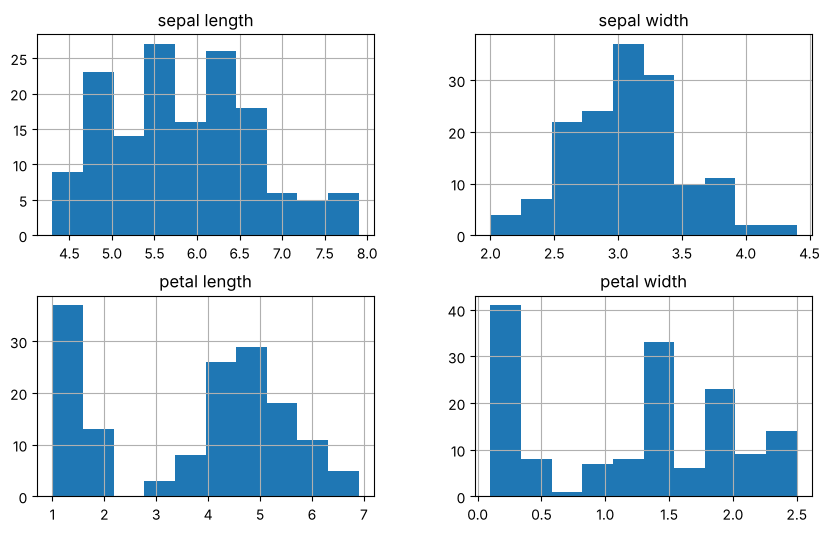

In [8]:
iris.hist(figsize=(10, 6));    # the final `;` suppresses the textual output

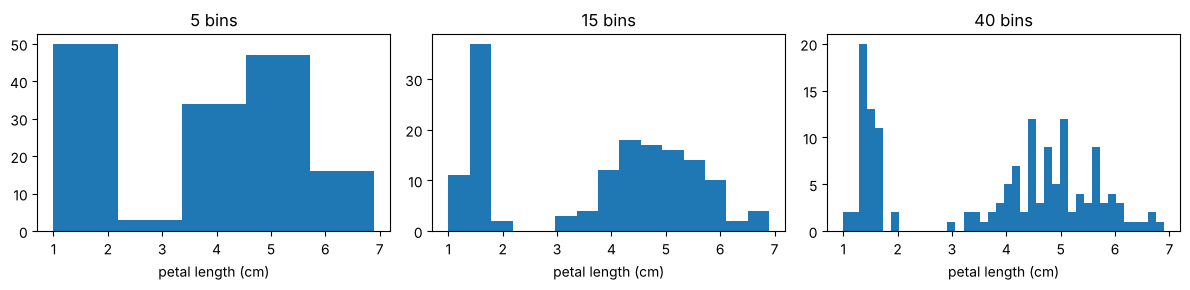

In [9]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3), sharey=False)
for ax, b in zip(axs, [5, 15, 40]):
    ax.hist(iris["petal length"], bins=b)
    ax.set_title(f"{b} bins")
    ax.set_xlabel("petal length (cm)")
plt.tight_layout()

**Answer.** With 5 bins petal length looks like one wide hump; with 15 or 40 bins two separate groups appear
(short petals around 1.5 cm, and the rest). Always try more than one bin width.

Make a box plot of the numeric features with the `boxplot()` method. The four columns share the same unit (cm), so one plot is fine.

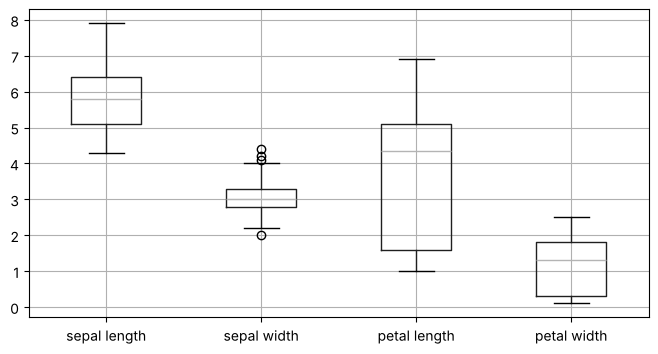

In [10]:
iris.boxplot();

## A3. Data quality: missing values, impossible values, outliers, duplicates

1. Count the missing values per column (`isna().sum()`). Could you already see it from `describe()`?
1. Are there impossible values (zero or negative lengths)?
1. Count the duplicated rows (`duplicated().sum()`) and show them (`iris[iris.duplicated(keep=False)]`).
1. The box plot of `sepal width` shows a few candidate outliers: are they errors?

In [11]:
print(iris.isna().sum())
print("non-positive values:", (iris.select_dtypes("number") <= 0).sum().sum())
print("duplicated rows:", iris.duplicated().sum())
iris[iris.duplicated(keep=False)]

sepal length    0
sepal width     0
petal length    0
petal width     0
class           0
dtype: int64
non-positive values: 0
duplicated rows: 1


,sepal length,sepal width,petal length,petal width,class
101,5.8,2.7,5.1,1.9,Iris-virginica
142,5.8,2.7,5.1,1.9,Iris-virginica


**Answer.** No missing values: the `count` row of `describe()` is 150 for every column. No zero or negative lengths.
There are a few duplicated rows: flowers with exactly the same measurements — with measurements rounded to 1 mm this is
plausible, not necessarily an error, so we keep them and note it.
The candidate outliers of sepal width are a few flowers with sepals slightly wider or narrower than the rest:
plausible values, *rare but real*, not errors.

## A4. The target: balance

Count the flowers of each class (`value_counts()`). What accuracy would the trivial model
"always predict the most frequent class" obtain?

In [12]:
counts = iris["class"].value_counts()
print(counts)
print(f"trivial model accuracy: {counts.max() / counts.sum():.0%}")

class
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64
trivial model accuracy: 33%


**Answer.** Perfectly balanced: 50 flowers per class. The trivial model is right one time in three (33%),
so here accuracy is a meaningful measure — unlike the imbalanced case we will see in Part B.

## A5. Each feature × target; correlations; confounders

### Box plots per class

Make a box plot of each feature grouped by class: add the `by` parameter to `boxplot()`.
Then compute the median of each feature per class with `groupby`.

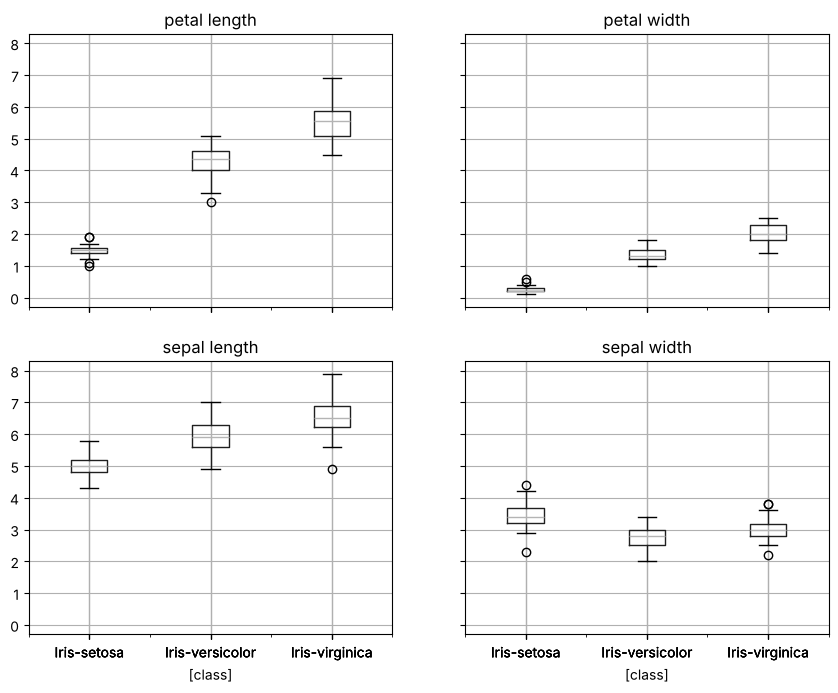

In [13]:
iris.boxplot(by="class", figsize=(10, 8))
plt.suptitle("");

In [14]:
iris.groupby("class").median()

,sepal length,sepal width,petal length,petal width
class,,,,
Iris-setosa,5.0,3.4,1.50,0.2
Iris-versicolor,5.9,2.8,4.35,1.3
Iris-virginica,6.5,3.0,5.55,2.0


**Question.** Which features separate the classes best? Which class is easiest to recognize?

**Answer.** Petal length and petal width: the boxes of *setosa* do not even overlap with the other two classes.
*Setosa* is the easiest class; *versicolor* and *virginica* overlap partially. Sepal width separates the classes least.

### Pair plot

The [`pairplot`](https://seaborn.pydata.org/generated/seaborn.pairplot.html) of the *seaborn* library shows a scatter plot
for every pair of numeric features, and the distribution of each feature on the diagonal.
Use the target as colour (`hue`), set `height=2` and `diag_kind="kde"`.

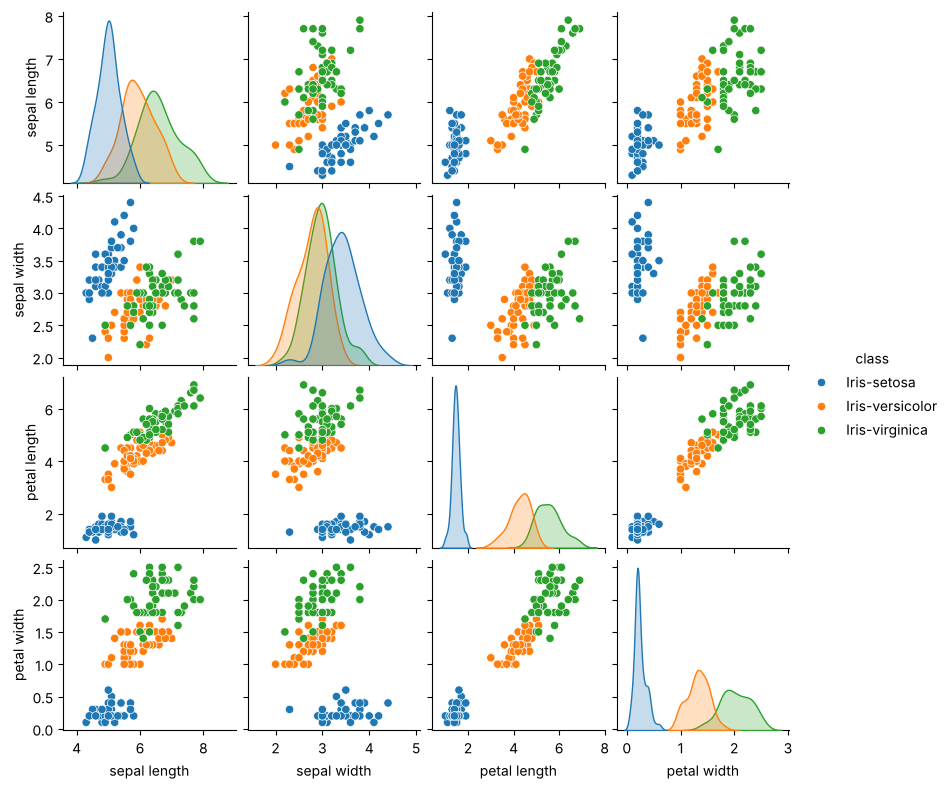

In [15]:
sns.pairplot(data=iris, hue="class", height=2, diag_kind="kde");

### Correlation matrix

Compute the Pearson correlation matrix of the numeric features (`corr(numeric_only=True)`),
then the Spearman one (`method="spearman"`). Show it as a heat map with `sns.heatmap(..., annot=True, vmin=-1, vmax=1, cmap="coolwarm")`.

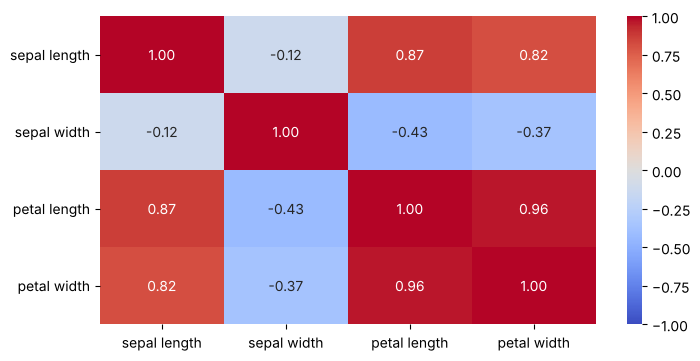

In [16]:
corr = iris.corr(numeric_only=True)
sns.heatmap(corr, annot=True, fmt=".2f", vmin=-1, vmax=1, cmap="coolwarm");

In [17]:
iris.corr(numeric_only=True, method="spearman")

,sepal length,sepal width,petal length,petal width
sepal length,1.00,-0.17,0.88,0.83
sepal width,-0.17,1.00,-0.31,-0.29
petal length,0.88,-0.31,1.00,0.94
petal width,0.83,-0.29,0.94,1.00


### A confounder in Iris ★

Compute the correlation between `sepal length` and `sepal width` on **all** flowers, then **within each class**.
Compare with the scatter plot of the two features in the pair plot. What is happening?

In [18]:
print(f"all flowers: {iris['sepal length'].corr(iris['sepal width']):.2f}")
for c, g in iris.groupby("class"):
    print(f"{c:16s} {g['sepal length'].corr(g['sepal width']):.2f}")

all flowers: -0.12
Iris-setosa      0.74
Iris-versicolor  0.53
Iris-virginica   0.46


**Answer.** On all flowers the correlation is slightly **negative** (about −0.1); within each species it is clearly **positive**
(about 0.45–0.75): within a species, longer sepals are also wider. The species is a confounder:
*setosa* has short but wide sepals, the other two long but narrower ones, and mixing the groups reverses the trend.
Always look within groups before trusting a correlation.

## A6. Findings

Complete the EDA log for Iris (double-click the cell to edit it).

| Finding | Evidence | Decision | Status |
|---|---|---|---|
| 4 ratio features (cm), 1 nominal target, no identifier | `info()` | none | done |
| no missing or impossible values | `isna().sum()`, `describe()` | none | done |
| duplicated rows | `duplicated()` | keep: plausible with 1 mm rounding | noted |
| classes balanced, 50 each | `value_counts()` | accuracy is meaningful here | noted |
| petal features separate the classes; setosa is separable | box plots by class, pair plot | hypothesis for the model | **open** |
| sepal length vs width: negative overall, positive within class | correlation per class | species is a confounder | noted |